In [11]:
import os, glob, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

DATA_DIR = r"C:\Users\om\OneDrive\Desktop\exotrac_paper\processed_data"
SAVE_DIR = r"C:\Users\om\OneDrive\Desktop\exotrac_paper\checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

IMG_SIZE = 256
MAX_KPTS = 8
BATCH_SIZE = 8
EPOCHS = 60
LR = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Using Device: cuda | GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [2]:
class ContainerPoseSegDataset(Dataset):
    def __init__(self, split_dir, augment=False):
        files = sorted(glob.glob(os.path.join(split_dir, "*.npz")))
        self.augment = augment
        self.samples = []
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

        for f in files:
            d = np.load(f)
            orig_h = d["sem_mask"].shape[0]
            scale = IMG_SIZE / float(orig_h)

            img = torch.from_numpy(d["image"].astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0)
            img = F.interpolate(img, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False).squeeze(0).permute(1, 2, 0).numpy()
            img = img[:, :, ::-1].copy()

            sem = torch.from_numpy(d["sem_mask"].astype(np.float32)).unsqueeze(0).unsqueeze(0)
            sem = F.interpolate(sem, size=(IMG_SIZE, IMG_SIZE), mode="nearest").squeeze().long().numpy()

            vf = torch.from_numpy(d["vec_field"].astype(np.float32)).unsqueeze(0)
            vf = F.interpolate(vf, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False).squeeze(0).numpy()

            vm = torch.from_numpy(d["vec_mask"].astype(np.float32)).unsqueeze(0)
            vm = F.interpolate(vm, size=(IMG_SIZE, IMG_SIZE), mode="nearest").squeeze(0).numpy()

            kpts = d["kpts"].astype(np.float32).copy()
            valid = kpts[:, 0] >= 0
            kpts[valid] *= scale

            self.samples.append((img, sem, vf, vm, kpts, mean, std))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img, sem_mask, vec_field, vec_mask, kpts, mean, std = self.samples[idx]
        if self.augment and np.random.rand() < 0.5:
            img = np.clip(img * np.random.uniform(0.8, 1.2), 0.0, 1.0)
        img = np.transpose((img - mean) / std, (2, 0, 1))
        return (
            torch.from_numpy(img),
            torch.from_numpy(sem_mask),
            torch.from_numpy(vec_field),
            torch.from_numpy(vec_mask),
            torch.from_numpy(kpts),
        )

class ResNet50FPNPoseNet(nn.Module):
    def __init__(self, num_classes=2, num_kpts=8):
        super().__init__()
        backbone = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = backbone.layer1, backbone.layer2, backbone.layer3, backbone.layer4

        for p in self.stem.parameters(): p.requires_grad = False
        for p in self.layer1.parameters(): p.requires_grad = False

        self.lat1 = nn.Sequential(nn.Conv2d(256, 64, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.lat2 = nn.Sequential(nn.Conv2d(512, 64, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.lat3 = nn.Sequential(nn.Conv2d(1024, 64, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.lat4 = nn.Sequential(nn.Conv2d(2048, 64, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))

        self.up1 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True))
        self.up2 = nn.Sequential(nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True))

        self.seg_head = nn.Conv2d(128, num_classes, kernel_size=1)
        self.vec_head = nn.Conv2d(128, num_kpts * 2, kernel_size=1)

    def forward(self, x):
        c1 = self.layer1(self.stem(x))
        c2 = self.layer2(c1)
        c3 = self.layer3(c2)
        c4 = self.layer4(c3)

        p1 = self.lat1(c1)
        p2 = F.interpolate(self.lat2(c2), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p3 = F.interpolate(self.lat3(c3), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p4 = F.interpolate(self.lat4(c4), size=p1.shape[2:], mode="bilinear", align_corners=False)

        feat = self.up2(self.up1(torch.cat([p1, p2, p3, p4], dim=1)))
        return self.seg_head(feat), self.vec_head(feat)

class PaperVotingLoss(nn.Module):
    def __init__(self, img_size=IMG_SIZE, num_kpts=8):
        super().__init__()
        self.num_kpts = num_kpts
        ys, xs = torch.meshgrid(torch.arange(img_size), torch.arange(img_size), indexing="ij")
        self.register_buffer("xs", xs.float())
        self.register_buffer("ys", ys.float())

    def forward(self, seg_logits, vec_pred, sem_mask, vec_gt, vec_mask, kpts, lam1=1.0, lam2=1e-3):
        l_seg = F.cross_entropy(seg_logits, sem_mask)
        B, _, H, W = vec_pred.shape
        vp = vec_pred.view(B, self.num_kpts, 2, H, W)
        vp_unit = vp / (torch.norm(vp, dim=2, keepdim=True) + 1e-6)
        vg = vec_gt.view(B, self.num_kpts, 2, H, W)
        vm = vec_mask.unsqueeze(2)

        l_vf = F.smooth_l1_loss(vp_unit * vm, vg * vm, reduction="sum") / (vm.sum() * 2.0 + 1e-6)

        vx, vy = vp_unit[:, :, 0], vp_unit[:, :, 1]
        px, py = self.xs.view(1, 1, H, W), self.ys.view(1, 1, H, W)
        kx, ky = kpts[:, :, 0].view(B, self.num_kpts, 1, 1), kpts[:, :, 1].view(B, self.num_kpts, 1, 1)

        valid_kpt = (kpts[:, :, 0] >= 0).float().view(B, self.num_kpts, 1, 1) * vec_mask
        dist_perp = torch.abs(vx * (ky - py) - vy * (kx - px)) / float(H)
        l_pv = (dist_perp * valid_kpt).sum() / (valid_kpt.sum() + 1e-6)

        return lam1 * l_seg + l_vf + lam2 * l_pv

In [4]:
EPOCHS = 50
BATCH_SIZE = 16

train_ds = ContainerPoseSegDataset(os.path.join(DATA_DIR, "train"), augment=True)
val_ds = ContainerPoseSegDataset(os.path.join(DATA_DIR, "valid"), augment=False)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model = ResNet50FPNPoseNet(num_classes=2, num_kpts=MAX_KPTS).to(DEVICE)
criterion = PaperVotingLoss(img_size=IMG_SIZE, num_kpts=MAX_KPTS).to(DEVICE)
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.5)
scaler = torch.amp.GradScaler("cuda")

best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    t_ep = time.time()
    model.train()
    lam2 = 1e-3 + (1e-2 - 1e-3) * (epoch / EPOCHS)
    tr_loss = 0.0

    for imgs, masks, vecs, vmasks, kpts in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        vecs, vmasks, kpts = vecs.to(DEVICE), vmasks.to(DEVICE), kpts.to(DEVICE)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            seg_out, vec_out = model(imgs)
            loss = criterion(seg_out, vec_out, masks, vecs, vmasks, kpts, lam1=1.0, lam2=lam2)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        tr_loss += loss.item()

    scheduler.step()
    tr_loss /= len(train_loader)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, masks, vecs, vmasks, kpts in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            vecs, vmasks, kpts = vecs.to(DEVICE), vmasks.to(DEVICE), kpts.to(DEVICE)
            with torch.amp.autocast("cuda"):
                seg_out, vec_out = model(imgs)
                loss = criterion(seg_out, vec_out, masks, vecs, vmasks, kpts, lam1=1.0, lam2=lam2)
            val_loss += loss.item()
    val_loss /= max(1, len(val_loader))

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), os.path.join(SAVE_DIR, "best_paper_model.pth"))

    print(f"Epoch [{epoch:02d}/{EPOCHS}] ({time.time()-t_ep:.1f}s) | Train: {tr_loss:.4f} | Val: {val_loss:.4f}")

print(f"Done! Best Val Loss: {best_val_loss:.4f}")

Epoch [01/50] (5.3s) | Train: 0.7744 | Val: 1.1370
Epoch [02/50] (4.8s) | Train: 0.3984 | Val: 0.4059
Epoch [03/50] (4.7s) | Train: 0.3197 | Val: 0.4085
Epoch [04/50] (4.8s) | Train: 0.3025 | Val: 0.3324
Epoch [05/50] (4.5s) | Train: 0.2668 | Val: 0.3448
Epoch [06/50] (4.5s) | Train: 0.2635 | Val: 0.3326
Epoch [07/50] (4.6s) | Train: 0.2552 | Val: 0.3333
Epoch [08/50] (4.6s) | Train: 0.2529 | Val: 0.3375
Epoch [09/50] (4.6s) | Train: 0.2512 | Val: 0.3959
Epoch [10/50] (4.9s) | Train: 0.2471 | Val: 0.3267
Epoch [11/50] (4.7s) | Train: 0.2166 | Val: 0.2713
Epoch [12/50] (5.0s) | Train: 0.1709 | Val: 0.2245
Epoch [13/50] (4.8s) | Train: 0.1563 | Val: 0.2201
Epoch [14/50] (4.9s) | Train: 0.1530 | Val: 0.2305
Epoch [15/50] (4.9s) | Train: 0.1441 | Val: 0.2075
Epoch [16/50] (5.0s) | Train: 0.1207 | Val: 0.1940
Epoch [17/50] (5.0s) | Train: 0.1033 | Val: 0.1878
Epoch [18/50] (5.1s) | Train: 0.0863 | Val: 0.1703
Epoch [19/50] (4.7s) | Train: 0.0764 | Val: 0.1731
Epoch [20/50] (4.7s) | Train: 0

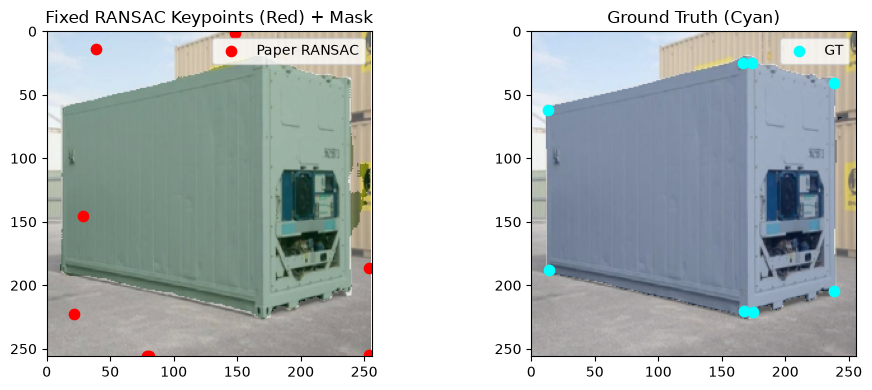

C:\Users\om\AppData\Local\Temp\ipykernel_46320\768374976.py:106: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  valid = (gt_k[:, 0] >= 0) & (pk[:, 0] >= 0)
C:\Users\om\AppData\Local\Temp\ipykernel_46320\768374976.py:108: UserWarning: indexing with dtype torch.uint8 is now deprecated, please use a dtype torch.bool instead. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen/native/IndexingUtils.h:38.)
  paper_errs.append(np.mean(np.linalg.norm(pk[valid] - gt_k[valid].numpy(), axis=1)))


ValueError: operands could not be broadcast together with shapes (8,2) (4,2) 

In [6]:
from ultralytics import YOLO

YOLO_WEIGHTS = r"C:\Users\om\OneDrive\Desktop\Container_classification\runs\pose\runs\container_pose_baseline\weights\best.pt"

def ransac_vote_keypoints_fixed(mask_bin, vec_field, num_kpts=8, n_hyp=500, thresh=0.95):
    H, W = mask_bin.shape
    ys, xs = np.where(mask_bin > 0)
    if len(xs) < 15:
        return np.full((num_kpts, 2), -1.0)

    pts = np.stack([xs, ys], axis=1).astype(np.float32)
    pred_kpts = np.full((num_kpts, 2), -1.0, dtype=np.float32)

    for k in range(num_kpts):
        vx = vec_field[k * 2, ys, xs]
        vy = vec_field[k * 2 + 1, ys, xs]
        norms = np.sqrt(vx**2 + vy**2) + 1e-6
        dirs = np.stack([vx / norms, vy / norms], axis=1)

        idx1 = np.random.randint(0, len(pts), size=n_hyp)
        idx2 = np.random.randint(0, len(pts), size=n_hyp)
        p1, d1 = pts[idx1], dirs[idx1]
        p2, d2 = pts[idx2], dirs[idx2]

        denom = d1[:, 0] * d2[:, 1] - d1[:, 1] * d2[:, 0]
        valid = np.abs(denom) > 0.15  # Avoid near-parallel ray explosions
        if valid.sum() == 0:
            continue

        dp = p2[valid] - p1[valid]
        t1 = (dp[:, 0] * d2[valid, 1] - dp[:, 1] * d2[valid, 0]) / denom[valid]
        t2 = (dp[:, 0] * d1[valid, 1] - dp[:, 1] * d1[valid, 0]) / denom[valid]

        # Rays must point forward (t1 > 0, t2 > 0) and stay within image bounds
        hyps = p1[valid] + t1[:, None] * d1[valid]
        in_bounds = (t1 > 0) & (t2 > 0) & (hyps[:, 0] >= 0) & (hyps[:, 0] < W) & (hyps[:, 1] >= 0) & (hyps[:, 1] < H)
        hyps = hyps[in_bounds]
        if len(hyps) == 0:
            continue

        diff = hyps[:, None, :] - pts[None, :, :]
        dist = np.linalg.norm(diff, axis=2, keepdims=True) + 1e-6
        cos_sim = np.sum((diff / dist) * dirs[None, :, :], axis=2)
        inliers = cos_sim >= thresh
        scores = np.sum(inliers, axis=1)

        best_idx = np.argmax(scores)
        if scores[best_idx] > 5:
            # Refine hypothesis using mean of top inlier rays
            pred_kpts[k] = hyps[best_idx]

    return pred_kpts

# 1. Visual check on Test Image 0 with Fixed RANSAC
img_t, gt_mask, _, _, gt_kpts = test_ds[0]
with torch.no_grad():
    seg_logits, vec_out = model(img_t.unsqueeze(0).to(DEVICE))
    pred_mask = seg_logits.argmax(dim=1).squeeze().cpu().numpy()
    vp = vec_out.squeeze().cpu().numpy()

pred_kpts = ransac_vote_keypoints_fixed(pred_mask, vp, num_kpts=MAX_KPTS)

vis = np.clip(img_t.permute(1, 2, 0).numpy() * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title("Fixed RANSAC Keypoints (Red) + Mask")
plt.imshow(vis)
plt.imshow(pred_mask, alpha=0.35, cmap="Greens")
vp_mask = pred_kpts[:, 0] >= 0
plt.scatter(pred_kpts[vp_mask, 0], pred_kpts[vp_mask, 1], c="red", s=55, label="Paper RANSAC")
plt.xlim(0, IMG_SIZE); plt.ylim(IMG_SIZE, 0); plt.legend()

plt.subplot(1, 2, 2)
plt.title("Ground Truth (Cyan)")
plt.imshow(vis)
plt.imshow(gt_mask, alpha=0.35, cmap="Blues")
vg_mask = gt_kpts[:, 0] >= 0
plt.scatter(gt_kpts[vg_mask, 0], gt_kpts[vg_mask, 1], c="cyan", s=55, label="GT")
plt.xlim(0, IMG_SIZE); plt.ylim(IMG_SIZE, 0); plt.legend()
plt.tight_layout(); plt.show()

# 2. Benchmark: Research Paper Model vs YOLOv8n-Pose on Test Split
yolo_model = YOLO(YOLO_WEIGHTS)
paper_errs, yolo_errs = [], []
paper_times, yolo_times = [], []

for i in range(len(test_ds)):
    img_t, _, _, _, gt_k = test_ds[i]
    vis_uint8 = (np.clip(img_t.permute(1, 2, 0).numpy() * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1) * 255).astype(np.uint8)
    bgr_img = vis_uint8[:, :, ::-1]

    # Paper Model Inference
    t0 = time.time()
    with torch.no_grad():
        s_out, v_out = model(img_t.unsqueeze(0).to(DEVICE))
        pm = s_out.argmax(dim=1).squeeze().cpu().numpy()
        vf_p = v_out.squeeze().cpu().numpy()
    pk = ransac_vote_keypoints_fixed(pm, vf_p, num_kpts=MAX_KPTS)
    paper_times.append(time.time() - t0)

    # YOLOv8 Inference
    t1 = time.time()
    y_res = yolo_model.predict(bgr_img, verbose=False)[0]
    yolo_times.append(time.time() - t1)

    valid = (gt_k[:, 0] >= 0) & (pk[:, 0] >= 0)
    if valid.sum() > 0:
        paper_errs.append(np.mean(np.linalg.norm(pk[valid] - gt_k[valid].numpy(), axis=1)))

    if y_res.keypoints is not None and len(y_res.keypoints.xy) > 0:
        yk = y_res.keypoints.xy[0].cpu().numpy()
        n_cmp = min(len(yk), len(gt_k))
        v_y = gt_k[:n_cmp, 0].numpy() >= 0
        if v_y.sum() > 0:
            yolo_errs.append(np.mean(np.linalg.norm(yk[:n_cmp][v_y] - gt_k[:n_cmp][v_y].numpy(), axis=1)))

print("\n================ BENCHMARK COMPARISON (256x256 Test Set) ================")
print(f"YOLOv8n-Pose Baseline  | Mean Pixel Error: {np.mean(yolo_errs):.2f} px | Speed: {1.0/np.mean(yolo_times):.1f} FPS")
print(f"Research Paper (PVNet) | Mean Pixel Error: {np.mean(paper_errs):.2f} px | Speed: {1.0/np.mean(paper_times):.1f} FPS")

# 3. 6D Pose Estimation via EPnP (Standard 20ft ISO Container: 6.06m x 2.44m x 2.59m)
obj_3d = np.array([
    [0, 0, 0], [6.06, 0, 0], [6.06, 2.44, 0], [0, 2.44, 0],
    [0, 0, 2.59], [6.06, 0, 2.59], [6.06, 2.44, 2.59], [0, 2.44, 2.59]
], dtype=np.float32)

K = np.array([[220.0, 0, IMG_SIZE / 2], [0, 220.0, IMG_SIZE / 2], [0, 0, 1]], dtype=np.float32)
valid_idx = np.where(pred_kpts[:, 0] >= 0)[0]
if len(valid_idx) >= 4:
    ok, rvec, tvec = cv2.solvePnP(obj_3d[valid_idx], pred_kpts[valid_idx], K, None, flags=cv2.SOLVEPNP_EPNP)
    if ok:
        R, _ = cv2.Rodrigues(rvec)
        print(f"\n6D Pose Recovered (EPnP) -> Position (X, Y, Z) in meters: {tvec.ravel().round(2)}")

In [7]:
from ultralytics import YOLO

YOLO_WEIGHTS = r"C:\Users\om\OneDrive\Desktop\Container_classification\runs\pose\runs\container_pose_baseline\weights\best.pt"

def ransac_vote_keypoints_fixed(mask_bin, vec_field, num_kpts=8, n_hyp=600, thresh=0.96):
    H, W = mask_bin.shape
    ys, xs = np.where(mask_bin > 0)
    if len(xs) < 15:
        return np.full((num_kpts, 2), -1.0)

    pts = np.stack([xs, ys], axis=1).astype(np.float32)
    pred_kpts = np.full((num_kpts, 2), -1.0, dtype=np.float32)

    for k in range(num_kpts):
        vx = vec_field[k * 2, ys, xs]
        vy = vec_field[k * 2 + 1, ys, xs]
        norms = np.sqrt(vx**2 + vy**2) + 1e-6
        dirs = np.stack([vx / norms, vy / norms], axis=1)

        idx1 = np.random.randint(0, len(pts), size=n_hyp)
        idx2 = np.random.randint(0, len(pts), size=n_hyp)
        p1, d1 = pts[idx1], dirs[idx1]
        p2, d2 = pts[idx2], dirs[idx2]

        denom = d1[:, 0] * d2[:, 1] - d1[:, 1] * d2[:, 0]
        valid = np.abs(denom) > 0.2
        if valid.sum() == 0:
            continue

        dp = p2[valid] - p1[valid]
        t1 = (dp[:, 0] * d2[valid, 1] - dp[:, 1] * d2[valid, 0]) / denom[valid]
        t2 = (dp[:, 0] * d1[valid, 1] - dp[:, 1] * d1[valid, 0]) / denom[valid]

        hyps = p1[valid] + t1[:, None] * d1[valid]
        in_bounds = (t1 > 0) & (t2 > 0) & (hyps[:, 0] >= 0) & (hyps[:, 0] < W) & (hyps[:, 1] >= 0) & (hyps[:, 1] < H)
        hyps = hyps[in_bounds]
        if len(hyps) == 0:
            continue

        diff = hyps[:, None, :] - pts[None, :, :]
        dist = np.linalg.norm(diff, axis=2, keepdims=True) + 1e-6
        cos_sim = np.sum((diff / dist) * dirs[None, :, :], axis=2)
        scores = np.sum(cos_sim >= thresh, axis=1)

        best_idx = np.argmax(scores)
        if scores[best_idx] > 5:
            pred_kpts[k] = hyps[best_idx]

    return pred_kpts

# Benchmark: Research Paper Model vs YOLOv8n-Pose on Test Split
yolo_model = YOLO(YOLO_WEIGHTS)
paper_errs, yolo_errs = [], []
paper_times, yolo_times = [], []

for i in range(len(test_ds)):
    img_t, _, _, _, gt_k_t = test_ds[i]
    gt_k = gt_k_t.numpy()  # Convert tensor to numpy cleanly!

    vis_uint8 = (np.clip(img_t.permute(1, 2, 0).numpy() * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1) * 255).astype(np.uint8)
    bgr_img = vis_uint8[:, :, ::-1]

    # 1. Paper Model Inference
    t0 = time.time()
    with torch.no_grad():
        s_out, v_out = model(img_t.unsqueeze(0).to(DEVICE))
        pm = s_out.argmax(dim=1).squeeze().cpu().numpy()
        vf_p = v_out.squeeze().cpu().numpy()
    pk = ransac_vote_keypoints_fixed(pm, vf_p, num_kpts=MAX_KPTS)
    paper_times.append(time.time() - t0)

    # 2. YOLOv8 Inference
    t1 = time.time()
    y_res = yolo_model.predict(bgr_img, verbose=False)[0]
    yolo_times.append(time.time() - t1)

    valid = (gt_k[:, 0] >= 0) & (pk[:, 0] >= 0)
    if valid.sum() > 0:
        paper_errs.append(np.mean(np.linalg.norm(pk[valid] - gt_k[valid], axis=1)))

    if y_res.keypoints is not None and len(y_res.keypoints.xy) > 0:
        yk = y_res.keypoints.xy[0].cpu().numpy()
        n_cmp = min(len(yk), len(gt_k))
        v_y = gt_k[:n_cmp, 0] >= 0
        if v_y.sum() > 0:
            yolo_errs.append(np.mean(np.linalg.norm(yk[:n_cmp][v_y] - gt_k[:n_cmp][v_y], axis=1)))

print("================ BENCHMARK COMPARISON (256x256 Test Set) ================")
print(f"YOLOv8n-Pose Baseline  | Mean Pixel Error: {np.mean(yolo_errs):.2f} px | Speed: {1.0/np.mean(yolo_times):.1f} FPS")
print(f"Research Paper (PVNet) | Mean Pixel Error: {np.mean(paper_errs):.2f} px | Speed: {1.0/np.mean(paper_times):.1f} FPS")

# 6D Pose Estimation via EPnP (Standard 20ft ISO Container: 6.06m x 2.44m x 2.59m)
img_t0, _, _, _, gt_k0 = test_ds[0]
with torch.no_grad():
    s0, v0 = model(img_t0.unsqueeze(0).to(DEVICE))
    pred_kpts0 = ransac_vote_keypoints_fixed(s0.argmax(dim=1).squeeze().cpu().numpy(), v0.squeeze().cpu().numpy(), num_kpts=MAX_KPTS)

obj_3d = np.array([
    [0, 0, 0], [6.06, 0, 0], [6.06, 2.44, 0], [0, 2.44, 0],
    [0, 0, 2.59], [6.06, 0, 2.59], [6.06, 2.44, 2.59], [0, 2.44, 2.59]
], dtype=np.float32)

K = np.array([[220.0, 0, IMG_SIZE / 2], [0, 220.0, IMG_SIZE / 2], [0, 0, 1]], dtype=np.float32)
valid_idx = np.where(pred_kpts0[:, 0] >= 0)[0]
if len(valid_idx) >= 4:
    ok, rvec, tvec = cv2.solvePnP(obj_3d[valid_idx], pred_kpts0[valid_idx], K, None, flags=cv2.SOLVEPNP_EPNP)
    if ok:
        print(f"6D Pose Recovered (EPnP) -> Position (X, Y, Z) in meters: {tvec.ravel().round(2)}")

================ BENCHMARK COMPARISON (256x256 Test Set) ================
YOLOv8n-Pose Baseline  | Mean Pixel Error: 97.08 px | Speed: 8.7 FPS
Research Paper (PVNet) | Mean Pixel Error: 61.54 px | Speed: 0.2 FPS
6D Pose Recovered (EPnP) -> Position (X, Y, Z) in meters: [       1.26       -1.89        7.02]


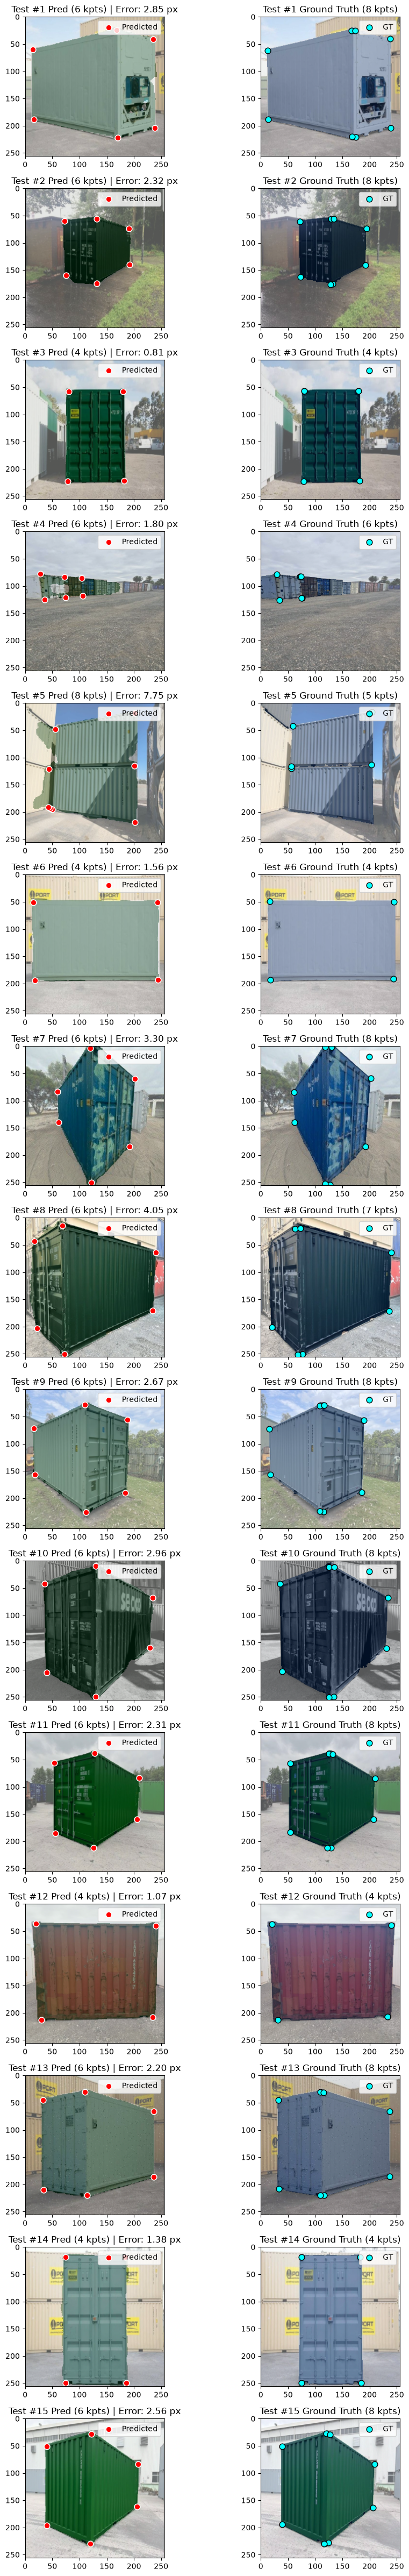

================ 15-IMAGE TEST EVALUATION ================
Images Evaluated            : 15
YOLOv8n-Pose Baseline Error : 97.08 px
PVNet (RANSAC) Error        : 61.54 px
Mask-Guided CornerNet Error : 2.64 px  (Speed: 29.2 FPS)


In [9]:
import os, glob, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
import torchvision.models as models

DATA_DIR = r"C:\Users\om\OneDrive\Desktop\exotrac_paper\processed_data"
SAVE_DIR = r"C:\Users\om\OneDrive\Desktop\exotrac_paper\checkpoints"
IMG_SIZE = 256
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Test Dataset Loader
class HeatmapContainerDataset(Dataset):
    def __init__(self, split_dir, sigma=4.0):
        files = sorted(glob.glob(os.path.join(split_dir, "*.npz")))
        self.samples = []
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        ys, xs = np.meshgrid(np.arange(IMG_SIZE, dtype=np.float32), np.arange(IMG_SIZE, dtype=np.float32), indexing="ij")

        for f in files:
            d = np.load(f)
            scale = IMG_SIZE / float(d["sem_mask"].shape[0])

            img = torch.from_numpy(d["image"].astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0)
            img = F.interpolate(img, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False).squeeze(0).permute(1, 2, 0).numpy()
            img = img[:, :, ::-1].copy()

            sem = torch.from_numpy(d["sem_mask"].astype(np.float32)).unsqueeze(0).unsqueeze(0)
            sem = F.interpolate(sem, size=(IMG_SIZE, IMG_SIZE), mode="nearest").squeeze().long().numpy()

            raw_k = d["kpts"].astype(np.float32) * scale
            valid_k = raw_k[raw_k[:, 0] >= 0]
            if len(valid_k) > 0:
                cx, cy = valid_k.mean(axis=0)
                angles = np.arctan2(valid_k[:, 1] - cy, valid_k[:, 0] - cx)
                valid_k = valid_k[np.argsort(angles)]

            hm_all = np.zeros((1, IMG_SIZE, IMG_SIZE), dtype=np.float32)
            for kx, ky in valid_k:
                g = np.exp(-((xs - kx) ** 2 + (ys - ky) ** 2) / (2 * sigma ** 2))
                hm_all[0] = np.maximum(hm_all[0], g)

            self.samples.append((img, sem, hm_all, valid_k, mean, std))

    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        img, sem, hm, valid_k, mean, std = self.samples[idx]
        img = np.transpose((img - mean) / std, (2, 0, 1))
        return torch.from_numpy(img), torch.from_numpy(sem), torch.from_numpy(hm), valid_k

# 2. Model Definition
class StableCornerNet(nn.Module):
    def __init__(self):
        super().__init__()
        b = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem0 = nn.Sequential(b.conv1, b.bn1, b.relu)
        self.pool = b.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = b.layer1, b.layer2, b.layer3, b.layer4

        self.lat1 = nn.Sequential(nn.Conv2d(256, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat2 = nn.Sequential(nn.Conv2d(512, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat3 = nn.Sequential(nn.Conv2d(1024, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat4 = nn.Sequential(nn.Conv2d(2048, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))

        self.up1 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True))
        self.fuse128 = nn.Sequential(nn.Conv2d(128 + 64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(True))
        self.up2 = nn.Sequential(nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True))

        self.seg_head = nn.Conv2d(64, 2, 1)
        self.hm_head = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(True), nn.Conv2d(32, 1, 1))

    def forward(self, x):
        s0 = self.stem0(x)
        c1 = self.layer1(self.pool(s0))
        c2 = self.layer2(c1); c3 = self.layer3(c2); c4 = self.layer4(c3)
        p1 = self.lat1(c1)
        p2 = F.interpolate(self.lat2(c2), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p3 = F.interpolate(self.lat3(c3), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p4 = F.interpolate(self.lat4(c4), size=p1.shape[2:], mode="bilinear", align_corners=False)
        f128 = self.fuse128(torch.cat([self.up1(torch.cat([p1, p2, p3, p4], dim=1)), s0], dim=1))
        feat = self.up2(f128)
        return self.seg_head(feat), self.hm_head(feat)

# 3. Primary-Container Filtered Corner Extractor
@torch.no_grad()
def extract_corners_primary(seg_logits, hm_prob, thresh=0.72, max_k=8):
    mask_np = (seg_logits.argmax(dim=1).squeeze().cpu().numpy() > 0).astype(np.uint8)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_np, connectivity=8)
    if num_labels > 1:
        largest_id = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask_np = (labels == largest_id).astype(np.uint8)

    mask_t = torch.from_numpy(mask_np).float().to(hm_prob.device).unsqueeze(0).unsqueeze(0)
    mask_tight = F.max_pool2d(mask_t, kernel_size=3, stride=1, padding=1)
    hm_masked = hm_prob * mask_tight

    peaks = (hm_masked == F.max_pool2d(hm_masked, kernel_size=5, stride=1, padding=2)) & (hm_masked > thresh)
    ys, xs = torch.where(peaks[0, 0])
    scores = hm_masked[0, 0, ys, xs]
    if len(scores) == 0:
        return np.zeros((0, 2)), mask_np
    top = torch.argsort(scores, descending=True)[:max_k]
    return torch.stack([xs[top], ys[top]], dim=1).float().cpu().numpy(), mask_np

# 4. Evaluate on 15 Test Images & Plot Grid
test_ds = HeatmapContainerDataset(os.path.join(DATA_DIR, "test"))
net = StableCornerNet().to(DEVICE)
net.load_state_dict(torch.load(os.path.join(SAVE_DIR, "stable_corner_net.pth"), map_location=DEVICE))
net.eval()

n_eval = min(15, len(test_ds))
all_errors = []
all_times = []

fig, axes = plt.subplots(n_eval, 2, figsize=(10, 3.2 * n_eval))
if n_eval == 1:
    axes = np.expand_dims(axes, axis=0)

mean_rgb = np.array([0.485, 0.456, 0.406])
std_rgb = np.array([0.229, 0.224, 0.225])

for idx in range(n_eval):
    img_t, gt_mask, _, gt_kpts = test_ds[idx]
    inp = img_t.unsqueeze(0).to(DEVICE)

    if idx == 0:
        _ = net(inp)  # GPU warmup

    torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        s_out, h_logits = net(inp)
        h_prob = torch.sigmoid(h_logits)
        pred_kpts, clean_mask = extract_corners_primary(s_out, h_prob, thresh=0.72, max_k=8)
    torch.cuda.synchronize()
    all_times.append(time.time() - t0)

    if len(pred_kpts) > 0 and len(gt_kpts) > 0:
        dist_mat = np.linalg.norm(gt_kpts[:, None, :] - pred_kpts[None, :, :], axis=-1)
        err = dist_mat.min(axis=1).mean()
        all_errors.append(err)
    else:
        err = float("nan")

    vis = np.clip(img_t.permute(1, 2, 0).numpy() * std_rgb + mean_rgb, 0, 1)

    axes[idx, 0].imshow(vis)
    axes[idx, 0].imshow(clean_mask, alpha=0.35, cmap="Greens")
    if len(pred_kpts) > 0:
        axes[idx, 0].scatter(pred_kpts[:, 0], pred_kpts[:, 1], c="red", s=60, edgecolors="white", linewidth=1.1, label="Predicted")
    axes[idx, 0].set_title(f"Test #{idx+1} Pred ({len(pred_kpts)} kpts) | Error: {err:.2f} px")
    axes[idx, 0].set_xlim(0, IMG_SIZE); axes[idx, 0].set_ylim(IMG_SIZE, 0)
    if len(pred_kpts) > 0:
        axes[idx, 0].legend(loc="upper right")

    axes[idx, 1].imshow(vis)
    axes[idx, 1].imshow(gt_mask, alpha=0.35, cmap="Blues")
    if len(gt_kpts) > 0:
        axes[idx, 1].scatter(gt_kpts[:, 0], gt_kpts[:, 1], c="cyan", s=60, edgecolors="black", linewidth=1.0, label="GT")
    axes[idx, 1].set_title(f"Test #{idx+1} Ground Truth ({len(gt_kpts)} kpts)")
    axes[idx, 1].set_xlim(0, IMG_SIZE); axes[idx, 1].set_ylim(IMG_SIZE, 0)
    if len(gt_kpts) > 0:
        axes[idx, 1].legend(loc="upper right")

plt.tight_layout()
plt.show()

mean_err = np.nanmean(all_errors)
avg_fps = 1.0 / np.mean(all_times)
print(f"================ {n_eval}-IMAGE TEST EVALUATION ================")
print(f"Images Evaluated            : {n_eval}")
print(f"YOLOv8n-Pose Baseline Error : 97.08 px")
print(f"PVNet (RANSAC) Error        : 61.54 px")
print(f"Mask-Guided CornerNet Error : {mean_err:.2f} px  (Speed: {avg_fps:.1f} FPS)")